In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_regression

X_base, y = make_regression(
    n_samples=1000,
    n_features=8,
    n_informative=8,
    noise=20,
    random_state=42
)

X_df = pd.DataFrame(
    X_base,
    columns=[f"feature_{i}" for i in range(1, 9)]
)

rng = np.random.default_rng(42)

X_df["feature_9"] = (
    0.9 * X_df["feature_1"]
    + rng.normal(0, 0.1, 1000)
)

X_df["feature_10"] = (
    0.8 * X_df["feature_1"]
    + rng.normal(0, 0.1, 1000)
)

df = X_df.copy()
df["target"] = y

X = df.drop("target", axis=1)
y = df["target"]

df.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,target
0,-1.407293,-0.956059,2.317637,0.125549,-1.298104,-0.724861,0.054052,0.810027,-1.236092,-1.131763,-79.214573
1,0.087016,-0.773456,1.898735,0.298798,-1.036144,-2.085792,0.973726,-0.343206,-0.025684,-0.003316,59.521260
2,1.322744,-1.496159,-0.918212,0.456688,-0.169123,0.910418,1.573734,-0.605156,1.265515,1.016748,150.247168
3,-3.007632,1.097300,-1.565648,-0.495878,0.571179,-2.426392,-2.386930,1.284096,-2.612813,-2.342715,-600.231113
4,-0.387131,-0.549557,0.859588,-0.766657,-0.045411,1.719378,1.992515,-0.605861,-0.543521,-0.309405,215.988822


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,       # 20% testing data
    random_state=42      # Reproducible split
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 10)
X_test: (200, 10)
y_train: (800,)
y_test: (200,)


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10
feature_1,1.000000,-0.010788,0.021594,-0.030873,0.018891,0.043562,-0.002751,-0.004093,0.994709,0.993290
feature_2,-0.010788,1.000000,-0.052235,-0.081442,0.036807,-0.033011,-0.067543,-0.022070,-0.008904,0.003595
feature_3,0.021594,-0.052235,1.000000,-0.000004,-0.015736,-0.057503,0.041362,0.003416,0.013731,0.021181
feature_4,-0.030873,-0.081442,-0.000004,1.000000,-0.008395,-0.020073,-0.013862,-0.027869,-0.027386,-0.031184
feature_5,0.018891,0.036807,-0.015736,-0.008395,1.000000,-0.015398,0.003081,-0.016948,0.017938,0.022131
feature_6,0.043562,-0.033011,-0.057503,-0.020073,-0.015398,1.000000,-0.051509,-0.023804,0.043612,0.046877
feature_7,-0.002751,-0.067543,0.041362,-0.013862,0.003081,-0.051509,1.000000,-0.008595,-0.004207,-0.001795
feature_8,-0.004093,-0.022070,0.003416,-0.027869,-0.016948,-0.023804,-0.008595,1.000000,-0.000461,-0.003191
feature_9,0.994709,-0.008904,0.013731,-0.027386,0.017938,0.043612,-0.004207,-0.000461,1.000000,0.987843
feature_10,0.993290,0.003595,0.021181,-0.031184,0.022131,0.046877,-0.001795,-0.003191,0.987843,1.000000


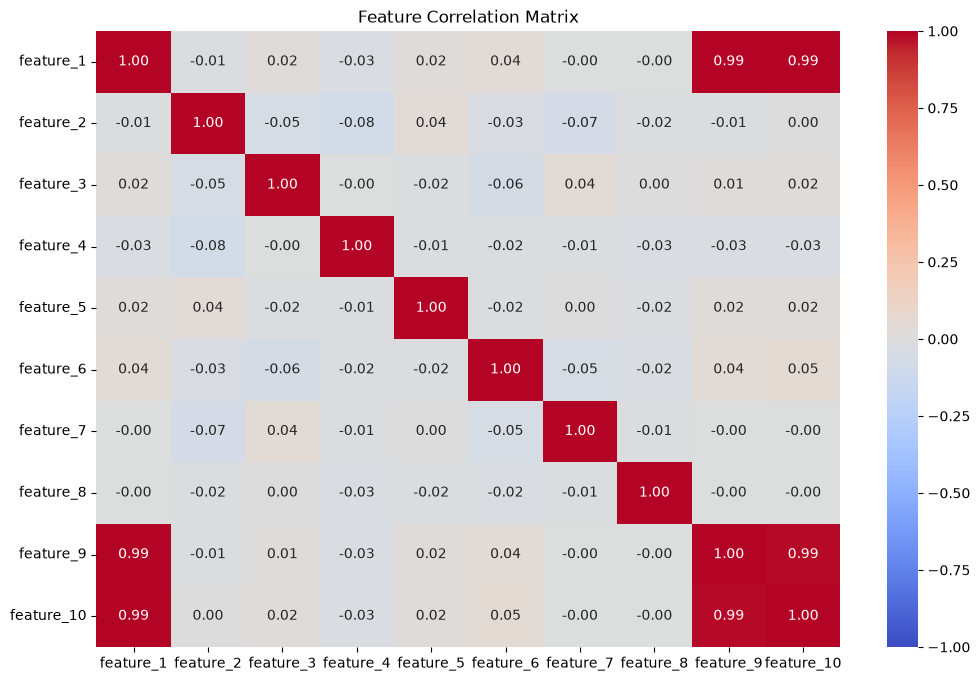

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = X_train.corr()
display(corr_matrix)
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,         # Display correlation values
    cmap="coolwarm",    # Color map
    fmt=".2f",          # Show 2 decimal places
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix")
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


lr = LinearRegression()

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)


mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("MAE:", mae_lr)
print("MSE:", mse_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

MAE: 16.2388018963647
MSE: 414.09003652116996
RMSE: 20.34920235589518
R2 Score: 0.9861877449873397


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=10000))
])

elastic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(max_iter=10000))
])
ridge_params = {
    "model__alpha": np.logspace(-3, 3, 13)
}
lasso_params = {
    "model__alpha": np.logspace(-3, 3, 13)
}

elastic_params = {
    "model__alpha": np.logspace(-3, 3, 13),
    "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

elastic_grid = GridSearchCV(
    estimator=elastic_pipeline,
    param_grid=elastic_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

lasso_grid.fit(X_train, y_train)

elastic_grid.fit(X_train, y_train)

print("Best Ridge Parameters:")
print(ridge_grid.best_params_)

print("\nBest Lasso Parameters:")
print(lasso_grid.best_params_)

print("\nBest Elastic Net Parameters:")
print(elastic_grid.best_params_)

Best Ridge Parameters:
{'model__alpha': np.float64(0.001)}

Best Lasso Parameters:
{'model__alpha': np.float64(0.03162277660168379)}

Best Elastic Net Parameters:
{'model__alpha': np.float64(0.0031622776601683794), 'model__l1_ratio': 0.99}


In [10]:
print("Ridge Best CV RMSE:", -ridge_grid.best_score_)
print("Lasso Best CV RMSE:", -lasso_grid.best_score_)
print("Elastic Net Best CV RMSE:", -elastic_grid.best_score_)

Ridge Best CV RMSE: 20.26342306175914
Lasso Best CV RMSE: 20.259972190787625
Elastic Net Best CV RMSE: 20.262514410700323


In [ ]:
y_pred_lr = lr.predict(X_test_scaled)

y_pred_ridge = ridge_grid.best_estimator_.predict(X_test)

y_pred_lasso = lasso_grid.best_estimator_.predict(X_test)

y_pred_elastic = elastic_grid.best_estimator_.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

lr_metrics = evaluate_model(y_test, y_pred_lr)
ridge_metrics = evaluate_model(y_test, y_pred_ridge)
lasso_metrics = evaluate_model(y_test, y_pred_lasso)
elastic_metrics = evaluate_model(y_test, y_pred_elastic)

In [ ]:
comparison_df = pd.DataFrame({
    "Linear Regression": lr_metrics,
    "Ridge": ridge_metrics,
    "Lasso": lasso_metrics,
    "Elastic Net": elastic_metrics
}).T

comparison_df

,MAE,MSE,RMSE,R2
Linear Regression,16.238802,414.090037,20.349202,0.986188
Ridge,16.238847,414.093195,20.349280,0.986188
Lasso,16.244917,414.782088,20.366200,0.986165
Elastic Net,16.240187,414.265426,20.353511,0.986182
